# Prédiction MVP & Top 20 Joueurs 2025
## XGBoost + SHAP + Dashboard interactif

In [1]:
# NOTEBOOK FINAL : PRÉDICTION MVP NBA ET RANKING DES MEILLEURS JOUEURS PAR SAISON
# Basé sur les features des joueurs (stats rolling, etc.)
# Modèle XGBoost pour classification (Is_MVP = 1 si MVP-1 dans Awards)
# Ranking : Probabilités prédites pour classer les joueurs

import pandas as pd
import numpy as np
import joblib
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix
from sklearn.inspection import permutation_importance

from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

import matplotlib.pyplot as plt
import seaborn as sns

print("LIBRAIRIES CHARGÉES – TOUT EST PRÊT !")

LIBRAIRIES CHARGÉES – TOUT EST PRÊT !


In [ ]:
# =============================
# 1. CHARGEMENT DATA
# =============================
df = pd.read_csv("C:\\Users\\isaid\\Downloads\\Python_Project_M1_BDIA\\Python_Project_M1_BDIA\\data\\features\\nba_players_features.csv")
df["Player"] = df["Player"].astype(str)  # Assurer que Player est string

print("Data :", df.shape)

Data : (8710, 39)


In [3]:
# =============================
# 2. CRÉATION DU TARGET : Is_MVP
# =============================
# On considère qu'un joueur est MVP si 'MVP-1' est dans Awards (gagnant MVP)
df['Is_MVP'] = df['Awards'].apply(lambda x: 1 if 'MVP-1' in str(x) else 0)

print("\nNombre de MVP dans le dataset :", df['Is_MVP'].sum())
print("Distribution des classes :\n", df['Is_MVP'].value_counts(normalize=True))


Nombre de MVP dans le dataset : 72
Distribution des classes :
 Is_MVP
0    0.991734
1    0.008266
Name: proportion, dtype: float64


In [4]:
# =============================
# 3. FEATURES SÉLECTIONNÉES (stats performantes, sans fuites)
# =============================
features = [
    'Age', 'G', 'GS', 'MP', 'FG', 'FGA', 'FG%', '3P', '3PA', '3P%', 
    '2P', '2PA', '2P%', 'eFG%', 'FT', 'FTA', 'FT%', 'ORB', 'DRB', 'TRB', 
    'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS', 
    'Rolling_PPG', 'Rolling_APG', 'Rolling_RPG', 'Rolling_3P%', 'Rolling_FG%', 'PPG_Improvement'
]

X = df[features]
y = df['Is_MVP']


In [5]:
# =============================
# 4. NETTOYAGE DES DONNÉES
# =============================
# Remplacer inf / -inf par NaN
X.replace([np.inf, -np.inf], np.nan, inplace=True)

# Optionnel : clipper les valeurs trop grandes
X = X.clip(-1e6, 1e6)

# Vérification des NaN
print("Nombre de NaN par colonne :\n", X.isna().sum())

Nombre de NaN par colonne :
 Age                 0
G                   0
GS                  0
MP                  0
FG                  0
FGA                 0
FG%                 0
3P                  0
3PA                 0
3P%                 0
2P                  0
2PA                 0
2P%                 0
eFG%                0
FT                  0
FTA                 0
FT%                 0
ORB                 0
DRB                 0
TRB                 0
AST                 0
STL                 0
BLK                 0
TOV                 0
PF                  0
PTS                 0
Rolling_PPG         0
Rolling_APG         0
Rolling_RPG         0
Rolling_3P%         0
Rolling_FG%         0
PPG_Improvement    72
dtype: int64


In [6]:
# =============================
# 5. SPLIT TRAIN/TEST (80/20)
# =============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nEntraînement : {len(X_train)} exemples")
print(f"Test        : {len(X_test)} exemples")

print("\nDistribution des classes (train / test):")
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))


Entraînement : 6968 exemples
Test        : 1742 exemples

Distribution des classes (train / test):
Is_MVP
0    0.991676
1    0.008324
Name: proportion, dtype: float64
Is_MVP
0    0.991963
1    0.008037
Name: proportion, dtype: float64


In [7]:
# =============================
# 6. PIPELINE & MODÈLES
# =============================
pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

models = {
    "XGBoost": XGBClassifier(
        use_label_encoder=False, eval_metric='logloss', random_state=42, scale_pos_weight=10
    ),
    "RandomForest": RandomForestClassifier(
        random_state=42, n_jobs=-1, class_weight='balanced'
    ),
    "LightGBM": LGBMClassifier(
        random_state=42, n_jobs=-1, class_weight='balanced'
    )
}


In [8]:
# =============================
# 7. ENTRAÎNEMENT ET ÉVALUATION
# =============================
results = {}
for name, clf in models.items():
    print(f"\n--- Entraînement : {name} ---")
    pipe_i = Pipeline(pipe.steps + [("clf", clf)])
    pipe_i.fit(X_train, y_train)
    
    y_proba_test = pipe_i.predict_proba(X_test)[:, 1]
    y_pred_test = pipe_i.predict(X_test)
    
    acc_test = accuracy_score(y_test, y_pred_test)
    auc_test = roc_auc_score(y_test, y_proba_test)
    
    print(f"Test Accuracy: {acc_test:.4f}")
    print(f"Test AUC     : {auc_test:.4f}")
    
    results[name] = {"pipeline": pipe_i, "acc": acc_test, "auc": auc_test}



--- Entraînement : XGBoost ---
Test Accuracy: 0.9879
Test AUC     : 0.9671

--- Entraînement : RandomForest ---
Test Accuracy: 0.9920
Test AUC     : 0.8658

--- Entraînement : LightGBM ---
[LightGBM] [Info] Number of positive: 58, number of negative: 6910
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002074 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7347
[LightGBM] [Info] Number of data points in the train set: 6968, number of used features: 32
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Test Accuracy: 0.9851
Test AUC     : 0.9715


In [9]:
# =============================
# 8. MEILLEUR MODÈLE
# =============================
best_name = max(results.keys(), key=lambda n: (results[n]['auc'], results[n]['acc']))
best_pipeline = results[best_name]['pipeline']
print(f"\nMEILLEUR MODÈLE (test) : {best_name} — Accuracy {results[best_name]['acc']:.4f}, AUC {results[best_name]['auc']:.4f}")


MEILLEUR MODÈLE (test) : LightGBM — Accuracy 0.9851, AUC 0.9715



Classification report (meilleur modèle):
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1728
           1       0.12      0.14      0.13        14

    accuracy                           0.99      1742
   macro avg       0.56      0.57      0.56      1742
weighted avg       0.99      0.99      0.99      1742



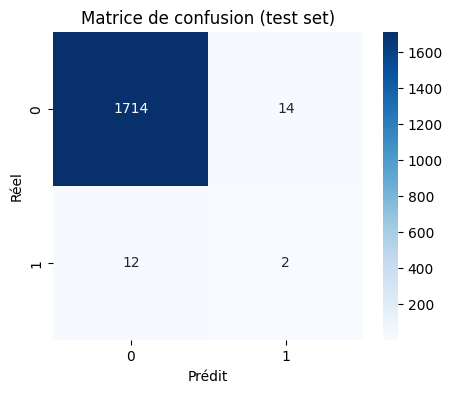

In [10]:
# =============================
# 9. RAPPORT DE CLASSIFICATION ET MATRICE DE CONFUSION
# =============================
y_pred_test = best_pipeline.predict(X_test)
print("\nClassification report (meilleur modèle):")
print(classification_report(y_test, y_pred_test))

cm = confusion_matrix(y_test, y_pred_test)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Matrice de confusion (test set)")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.show()



Permutation importance (test):
            feature  importance
24               PF    0.003215
7                3P    0.000890
5               FGA    0.000057
3                MP    0.000029
31  PPG_Improvement   -0.000086
17              ORB   -0.000144
25              PTS   -0.000545
12              2P%   -0.000603
9               3P%   -0.000660
18              DRB   -0.000689
8               3PA   -0.000890
1                 G   -0.000976
13             eFG%   -0.001148
2                GS   -0.001349
22              BLK   -0.001349
29      Rolling_3P%   -0.001406
11              2PA   -0.001464
16              FT%   -0.001493
21              STL   -0.001493
10               2P   -0.002153
19              TRB   -0.002268
0               Age   -0.002382
28      Rolling_RPG   -0.002698
6               FG%   -0.002813
30      Rolling_FG%   -0.003387
20              AST   -0.004248
27      Rolling_APG   -0.004937
15              FTA   -0.005224
4                FG   -0.005654
14      

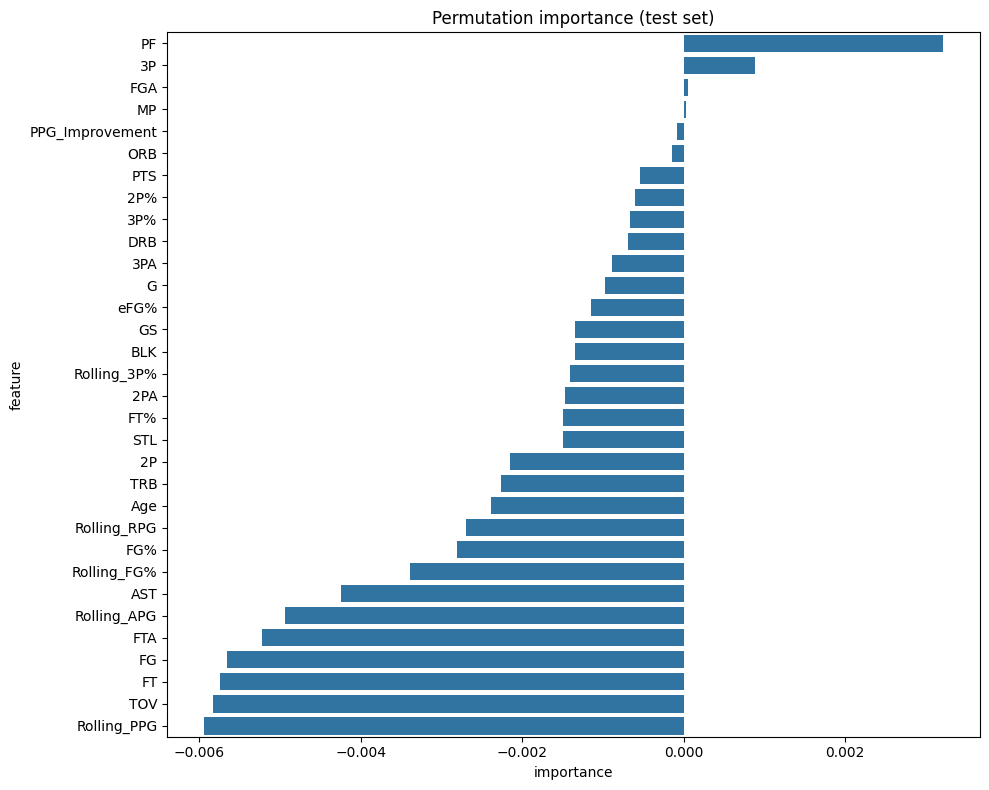

In [11]:
# =============================
# 10. IMPORTANCE DES FEATURES (PERMUTATION)
# =============================
r = permutation_importance(best_pipeline, X_test, y_test, n_repeats=20, random_state=42, n_jobs=-1)
imp_df = pd.DataFrame({"feature": features, "importance": r.importances_mean}).sort_values("importance", ascending=False)
print("\nPermutation importance (test):")
print(imp_df)

plt.figure(figsize=(10,8))
sns.barplot(data=imp_df, x="importance", y="feature")
plt.title("Permutation importance (test set)")
plt.tight_layout()
plt.show()


In [12]:
# =============================
# 11. OPTIONNEL : RANDOMIZEDSEARCH XGBOOST
# =============================
do_search = False
if do_search:
    xgb = XGBClassifier(
        use_label_encoder=False, eval_metric='logloss', random_state=42, scale_pos_weight=10
    )
    param_dist = {
        "n_estimators": [100, 200, 500],
        "max_depth": [3, 5, 7],
        "learning_rate": [0.01, 0.05, 0.1],
        "subsample": [0.6, 0.8, 1.0],
        "colsample_bytree": [0.6, 0.8, 1.0]
    }
    pipe_search = Pipeline(pipe.steps + [("clf", xgb)])
    rs = RandomizedSearchCV(
        pipe_search, {"clf__" + k: v for k, v in param_dist.items()},
        n_iter=12, cv=5, scoring="roc_auc", verbose=1, n_jobs=-1, random_state=42
    )
    rs.fit(X_train, y_train)
    print("Best params:", rs.best_params_)
    best_pipeline = rs.best_estimator_
    print("Updated best pipeline from RandomizedSearch.")


In [13]:
# =============================
# 12. SAUVEGARDE DU MEILLEUR MODÈLE
# =============================
MODEL_PATH = "best_mvp_model_pipeline.joblib"
joblib.dump(best_pipeline, MODEL_PATH)
print(f"Meilleur pipeline sauvegardé -> {MODEL_PATH}")

Meilleur pipeline sauvegardé -> best_mvp_model_pipeline.joblib


In [14]:
# =============================
# 13. FONCTION DE PRÉDICTION MVP ET RANKING PAR SAISON
# =============================
def predict_mvp_ranking(df_input=None, season=None, top_n=10, min_games=50, verbose=True):
    if df_input is None:
        df_input = df.copy()

    # Remplacer inf / -inf
    df_input.replace([np.inf, -np.inf], np.nan, inplace=True)

    # Filtrer par saison
    if season is not None:
        df_input = df_input[df_input['Season'] == season]
        if df_input.empty:
            print(f"Aucun joueur trouvé pour la saison {season}.")
            return pd.DataFrame()

    # Filtrer par nombre de matchs
    df_input = df_input[df_input['G'] >= min_games]
    if df_input.empty:
        print(f"Aucun joueur valide pour la saison {season} avec min {min_games} matchs.")
        return pd.DataFrame()

    X_input = df_input[features]
    df_input['MVP_Proba'] = best_pipeline.predict_proba(X_input)[:, 1]

    ranking = df_input.sort_values('MVP_Proba', ascending=False)[
        ['Player', 'Age', 'Team', 'PTS', 'AST', 'TRB', 'MVP_Proba']
    ]

    if verbose:
        title = f"RANKING DES MEILLEURS JOUEURS – Saison {season}" if season else "RANKING DES MEILLEURS JOUEURS (historique)"
        print("\n" + title + "\n" + "="*50)
        print(ranking.head(top_n))

    return ranking

In [15]:
# =============================
# 14. TEST RAPIDE : Ranking sur la dernière saison
# =============================
latest_season = df['Season'].max()
ranking_latest = predict_mvp_ranking(season=latest_season)


RANKING DES MEILLEURS JOUEURS – Saison 2024-2025
                       Player   Age Team     PTS    AST    TRB  MVP_Proba
6412            Nikola JokiÄ  28.0  DEN  2085.0  708.0  976.0   0.936416
1942            DeMar DeRozan  34.0  CHI  1897.0  421.0  340.0   0.796447
4931             Kevin Durant  35.0  PHO  2032.0  378.0  495.0   0.636825
2001          Dejounte Murray  27.0  ATL  1753.0  502.0  416.0   0.177955
3517            Jalen Brunson  27.0  NYK  2212.0  519.0  278.0   0.056827
7460  Shai Gilgeous-Alexander  25.0  OKC  2254.0  465.0  415.0   0.046020
454             Anthony Davis  30.0  LAL  1876.0  266.0  961.0   0.038492
2922    Giannis Antetokounmpo  29.0  MIL  2222.0  476.0  841.0   0.028481
5354             LeBron James  39.0  LAL  1822.0  589.0  518.0   0.026575
4126             Jimmy Butler  34.0  MIA  1246.0  298.0  318.0   0.017501
